# Neural Baseline

In [2]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

print("torch", torch.__version__)
print("numpy", np.__version__, "| pandas", pd.__version__)

# reproducibility
SEED = 0
np.random.seed(SEED)
torch.manual_seed(SEED)

torch 2.14.1
numpy 2.5.2 | pandas 3.0.5


### Loading data

In [ ]:
# load cleaned data
clean = pd.read_csv("../data/processed/dec_clean.csv", parse_dates=["day_earnings"])

# keep only calls that have a company baseline (drops each company's first call)
data = clean.dropna(subset=["surprise3_q"]).reset_index(drop=True)
print("calls with a target:", len(data))
print(data["split"].value_counts())       

# load the three embedding sets
def load_emb(name):
    z = np.load(f"../data/Embeddings/openai/{name}.npz", allow_pickle=True)
    emb = pd.DataFrame(z["embeddings"], index=z["ids"].astype(str))
    return emb.loc[data["id"].tolist()].to_numpy(dtype=np.float32)

X_sets = {
    "real":          load_emb("DEC"),
    "random_ticker": load_emb("DEC2RandomTicker"),
    "random_all":    load_emb("DECRandomAll"),
}
for k, v in X_sets.items():
    print(k, v.shape)                         

y = data["surprise3_q"].to_numpy(dtype=np.float32)
split = data["split"].to_numpy(dtype=str)
print("target mean/std:", y.mean().round(3), y.std().round(3))

calls with a target: 1710
split
train    990
val      360
test     360
Name: count, dtype: int64
real (1710, 3072)
random_ticker (1710, 3072)
random_all (1710, 3072)
target mean/std: -0.0 0.747


### Standardize inputs, wrap them in a dataset/dataloader

In [ ]:
# standardize using training statistics only to prevent leakage
def standardize(X, split):
    tr = split == "train"
    mu = X[tr].mean(axis=0)
    # small constant to avoid dividing by 0
    sd = X[tr].std(axis=0) + 1e-8          
    return (X - mu) / sd

X_std = {k: standardize(v, split) for k, v in X_sets.items()}
print("real, train mean/std:", X_std["real"][split == "train"].mean().round(3),
      X_std["real"][split == "train"].std().round(3))     # expect ~0 and ~1

# Dataset + DataLoader 
class CallDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.from_numpy(X)
        self.y = torch.from_numpy(y).unsqueeze(1)         
    def __len__(self):
        return len(self.y)

    def __getitem__(self, i):
        return self.X[i], self.y[i]

def make_loaders(X, batch_size=64):
    loaders = {}
    for s in ["train", "val", "test"]:
        m = split == s
        loaders[s] = DataLoader(CallDataset(X[m], y[m]),
                                batch_size=batch_size,
                                shuffle=(s == "train"))     # shuffle only the training data
    return loaders

loaders = make_loaders(X_std["real"])
xb, yb = next(iter(loaders["train"]))
print("one batch:", xb.shape, yb.shape)                    # expect (64, 3072) and (64, 1)

real, train mean/std: 0.0 1.0
one batch: torch.Size([64, 3072]) torch.Size([64, 1])


### Model, and Tiny overfit check

In [ ]:
# the model 
def make_model(in_dim=3072, hidden=64, dropout=0.3):
    layers = [nn.Linear(in_dim, hidden), nn.ReLU()]
    if dropout > 0:
        layers.append(nn.Dropout(dropout))
    layers.append(nn.Linear(hidden, 1))            # one output: the predicted surprise (no activation, it's regression)
    return nn.Sequential(*layers)

model = make_model()
print(model)
print("parameters:", sum(p.numel() for p in model.parameters()))

# tiny overfit and sanity check
# If the pipeline is correct, the model should memorize 32 calls almost perfectly.
torch.manual_seed(SEED)
tr = split == "train"
X_tiny = torch.from_numpy(X_std["real"][tr][:32])
y_tiny = torch.from_numpy(y[tr][:32]).unsqueeze(1)

tiny_model = make_model(dropout=0)               
opt = torch.optim.Adam(tiny_model.parameters(), lr=1e-3)
loss_fn = nn.MSELoss()

for step in range(500):
    opt.zero_grad()
    loss = loss_fn(tiny_model(X_tiny), y_tiny)
    loss.backward()
    opt.step()
    if step % 100 == 0 or step == 499:
        print(f"step {step:3d}  loss {loss.item():.5f}")

Sequential(
  (0): Linear(in_features=3072, out_features=64, bias=True)
  (1): ReLU()
  (2): Dropout(p=0.3, inplace=False)
  (3): Linear(in_features=64, out_features=1, bias=True)
)
parameters: 196737
step   0  loss 0.65561
step 100  loss 0.00020
step 200  loss 0.00018
step 300  loss 0.00017
step 400  loss 0.00016
step 499  loss 0.00015


Tiny overfit check passed. Loss fell from .66 to .0002, so the model, loss, and update steps are wired correctly. 

### Full training loop with early stopping, and first test result

stopped after 26 epochs, best epoch 5
{'test_mse': 0.6227, 'baseline_mse': 0.5254, 'spearman': 0.0804, 'pred_std': 0.3722, 'target_std': 0.7249}


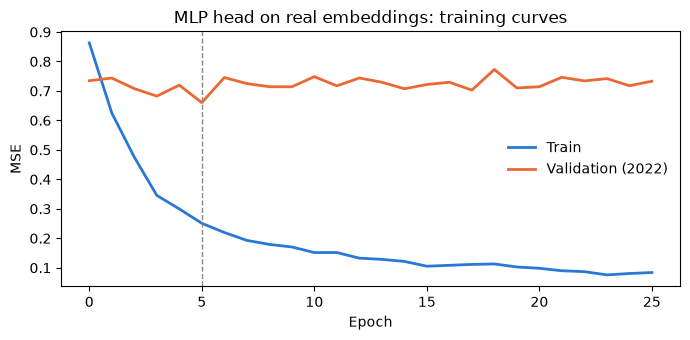

In [ ]:
from scipy.stats import spearmanr
import matplotlib.pyplot as plt
BLUE, ORANGE, MUTED = "#2a78d6", "#eb6834", "#8a8984"

# one training epoch 
def train_one_epoch(model, loader, opt, loss_fn):
    model.train()      
    total = 0.0
    for xb, yb in loader:
        opt.zero_grad()
        loss = loss_fn(model(xb), yb)
        loss.backward()
        opt.step()
        total += loss.item() * len(yb)
    return total / len(loader.dataset)

# evaluation 
@torch.no_grad()
def predict(model, loader):
    model.eval()   
    preds, ys = [], []
    for xb, yb in loader:
        preds.append(model(xb))
        ys.append(yb)
    return torch.cat(preds).squeeze(1).numpy(), torch.cat(ys).squeeze(1).numpy()

def mse(p, t):
    return float(np.mean((p - t) ** 2))

# full training, with early stopping
def train_model(X, seed=0, hidden=64, dropout=0.3, opt_name="adam", lr=1e-3,
                weight_decay=1e-4, batch_size=64, max_epochs=200, patience=20):
    torch.manual_seed(seed); np.random.seed(seed)
    loaders = make_loaders(X, batch_size)
    model = make_model(X.shape[1], hidden, dropout)
    if opt_name == "adam":
        opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    else:
        opt = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9, weight_decay=weight_decay)
    loss_fn = nn.MSELoss()

    best_val, best_state, wait = float("inf"), None, 0
    history = {"train": [], "val": []}
    for epoch in range(max_epochs):
        history["train"].append(train_one_epoch(model, loaders["train"], opt, loss_fn))
        p_val, y_val = predict(model, loaders["val"])
        val_loss = mse(p_val, y_val)
        history["val"].append(val_loss)
        if val_loss < best_val:
            best_val, wait = val_loss, 0
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()} 
        else:
            wait += 1
            if wait >= patience:
                break
    model.load_state_dict(best_state)     
    return model, history, loaders

# evaluate on the 2023 test set
def evaluate(model, loaders):
    p, t = predict(model, loaders["test"])
    return {"test_mse": mse(p, t),
            "baseline_mse": mse(np.zeros_like(t), t),  
            "spearman": float(spearmanr(p, t)[0]),
            "pred_std": float(p.std()), "target_std": float(t.std())}

# --- First run: real embeddings, one seed ---
model, hist, loaders = train_model(X_std["real"], seed=0)
res = evaluate(model, loaders)
best_epoch = int(np.argmin(hist["val"]))
print(f"stopped after {len(hist['val'])} epochs, best epoch {best_epoch}")
print({k: round(v, 4) for k, v in res.items()})

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(hist["train"], color=BLUE, lw=2, label="Train")
ax.plot(hist["val"], color=ORANGE, lw=2, label="Validation (2022)")
ax.axvline(best_epoch, color=MUTED, ls="--", lw=1)
ax.set(xlabel="Epoch", ylabel="MSE", title="MLP head on real embeddings: training curves")
ax.legend(frameon=False); plt.tight_layout(); plt.show()

The model is overfitting. Training loss falls to .08, while validation never improves, it just bounces around .7. The best epoch was 5 which looks like just noise in the validation curve

This is worse than the baseline. Test MSE is 0.623 vs 0.525 for predicting zero surprisem about 19% worse. Predictions vary quit a bit (standard deviation of 0.37), but they're mostly noise, and confident noise adds error. 

Spearman +.08 is about 1.5 standard errors from zero

### Tuning regularization on validation only

In [7]:
import itertools, time

# zero-surprise baseline on validation, for reference
y_val = y[split == "val"]
print("val baseline MSE:", round(mse(np.zeros_like(y_val), y_val), 4))

grid = list(itertools.product([16, 64],            # hidden units
                              [0.3, 0.5],          # dropout
                              [1e-3, 1e-2, 1e-1],  # weight decay
                              [1e-3, 1e-4]))       # learning rate
rows = []
t0 = time.time()
for hidden, dropout, wd, lr in grid:
    model, hist, loaders = train_model(X_std["real"], seed=0, hidden=hidden,
                                       dropout=dropout, weight_decay=wd, lr=lr)
    p_val, t_val = predict(model, loaders["val"])
    rows.append({"hidden": hidden, "dropout": dropout, "weight_decay": wd, "lr": lr,
                 "val_mse": mse(p_val, t_val), "pred_std": float(p_val.std()),
                 "epochs": len(hist["val"])})
grid_df = pd.DataFrame(rows).sort_values("val_mse")
print(f"{len(grid)} configs in {time.time() - t0:.0f}s")
print(grid_df.head(8).round(4).to_string(index=False))

val baseline MSE: 0.5433
24 configs in 6s
 hidden  dropout  weight_decay     lr  val_mse  pred_std  epochs
     16      0.5         0.100 0.0001   0.5761    0.1166      22
     16      0.5         0.010 0.0001   0.5763    0.1180      22
     16      0.5         0.001 0.0001   0.5765    0.1183      22
     16      0.5         0.001 0.0010   0.5816    0.2144      22
     16      0.3         0.100 0.0001   0.5825    0.1417      23
     16      0.3         0.010 0.0001   0.5836    0.1444      23
     16      0.3         0.001 0.0001   0.5838    0.1446      23
     16      0.5         0.010 0.0010   0.5850    0.2160      22


None of the 24 configuarations beats predicting zero on validation. The best is 0.576 vs a baseline of 0.543. Three patterns stand out:

- The winners are the most constrained settings: 16 hidden units, dropout 0.5, the lowst learning rate
- Early stopping fires almost immediately: 22 epochs with patience 20 meanss the best epoch was epoch 2
- Weight decay barely matters at the low learning rate because the model trains for so few epochs

### Using PCA to compress the embeddings into their main directions, fit on training data

In [8]:
def pca_inputs(X, k):
    tr = split == "train"
    mu = X[tr].mean(axis=0)
    _, _, Vt = np.linalg.svd(X[tr] - mu, full_matrices=False)   # fit on train only
    Z = ((X - mu) @ Vt[:k].T).astype(np.float32)
    return standardize(Z, split)

inputs = {"full": X_std["real"],
          "pca128": pca_inputs(X_std["real"], 128),
          "pca32": pca_inputs(X_std["real"], 32)}

rows = []
for (name, Xin), hidden, dropout, lr in itertools.product(inputs.items(), [4, 16], [0.5, 0.7], [1e-4, 1e-5]):
    model, hist, loaders = train_model(Xin, seed=0, hidden=hidden, dropout=dropout,
                                       weight_decay=1e-2, lr=lr)
    p_val, t_val = predict(model, loaders["val"])
    rows.append({"input": name, "hidden": hidden, "dropout": dropout, "lr": lr,
                 "val_mse": mse(p_val, t_val), "pred_std": float(p_val.std()),
                 "best_epoch": int(np.argmin(hist["val"]))})
grid2 = pd.DataFrame(rows).sort_values("val_mse")
print(grid2.head(8).round(4).to_string(index=False))

 input  hidden  dropout     lr  val_mse  pred_std  best_epoch
 pca32       4      0.7 0.0001   0.5481    0.0388         199
pca128       4      0.7 0.0001   0.5500    0.0561         122
 pca32       4      0.5 0.0001   0.5514    0.0585         148
 pca32      16      0.7 0.0001   0.5518    0.0950          55
  full       4      0.7 0.0000   0.5534    0.1158          57
 pca32      16      0.5 0.0001   0.5545    0.1075          41
pca128       4      0.5 0.0001   0.5550    0.0792          94
 pca32      16      0.7 0.0000   0.5552    0.1384         199


The best configuration of PCA to 32 dimensions, 4 hidden units, dropout of 0.7 reaches 0.548 validation MSE which is slightly weaker than the baseline. 

The prediction spread of 0.039 indicates it's almost predicting zero for every call

The more the network is constrained, the closer it gets to the baseline because it's converging on predict no surprise

Locked configuartionL
- Input: standardized embeddings, then PCA to 32 dimensions (fit on training data only)
- Model: MLP 32 -> 4 -> 1, ReLU, dropout 0.7
- Training: Adam, learning rate 1e-4, weight decay 1e-2, batch size 64, up to 400 epochs, early stopping on validation with a patience of 20

### Identity Removed Input

In [ ]:
# Identity-removed input: each call's embedding minus the company's average PAST embedding
full = clean.sort_values(["ticker", "day_earnings"]).reset_index(drop=True)
z = np.load("../data/Embeddings/openai/DEC.npz", allow_pickle=True)
E_all = pd.DataFrame(z["embeddings"], index=z["ids"].astype(str)).loc[full["id"].tolist()].to_numpy(np.float32)

tick = full["ticker"].to_numpy(dtype=str)
delta = np.full_like(E_all, np.nan)
for t in np.unique(tick):
    idx = np.where(tick == t)[0]                        
    cumsum = np.cumsum(E_all[idx], axis=0)
    n_past = np.arange(1, len(idx))[:, None]            
    past_mean = cumsum[:-1] / n_past   
    delta[idx[1:]] = E_all[idx[1:]] - past_mean   
X_delta = pd.DataFrame(delta, index=full["id"].tolist()).loc[data["id"].tolist()].to_numpy(np.float32)
print("identity-removed:", X_delta.shape, "NaNs:", np.isnan(X_delta).sum())   # expect (1710, 3072), 0 NaNs

X_sets["identity_removed"] = X_delta
X_final = {k: pca_inputs(standardize(v, split), 32) for k, v in X_sets.items()}

# All four inputs x 5 seeds with the locked configuration
CFG = dict(hidden=4, dropout=0.7, lr=1e-4, weight_decay=1e-2, max_epochs=400, patience=20)
runs = []
for name, Xin in X_final.items():
    for seed in range(5):
        model, hist, loaders = train_model(Xin, seed=seed, **CFG)
        r = evaluate(model, loaders)
        r.update(input=name, seed=seed, best_epoch=int(np.argmin(hist["val"])))
        runs.append(r)
runs_df = pd.DataFrame(runs)
runs_df["r2_vs_baseline"] = 1 - runs_df["test_mse"] / runs_df["baseline_mse"]

summary = (runs_df.groupby("input")[["test_mse", "r2_vs_baseline", "spearman", "pred_std"]]
                  .agg(["mean", "std"]).round(4))
print("zero-surprise baseline test MSE:", round(runs_df["baseline_mse"].iloc[0], 4))
print(summary.to_string())

import os; os.makedirs("../results", exist_ok=True)
runs_df.to_csv("../results/ci2_runs.csv", index=False)

identity-removed: (1710, 3072) NaNs: 0
zero-surprise baseline test MSE: 0.5254
                 test_mse         r2_vs_baseline         spearman         pred_std        
                     mean     std           mean     std     mean     std     mean     std
input                                                                                     
identity_removed   0.5268  0.0021        -0.0026  0.0040   0.0052  0.0547   0.0323  0.0046
random_all         0.5251  0.0014         0.0006  0.0026   0.0400  0.0412   0.0324  0.0034
random_ticker      0.5332  0.0024        -0.0148  0.0046  -0.0743  0.0351   0.0468  0.0034
real               0.5275  0.0042        -0.0040  0.0080  -0.0105  0.0561   0.0420  0.0083


- Nothing beats predicting zero
- Every model predicts close to nothing
- Random ticker is the worst
- Identity removes is roughly equal to the real which is roughly equal to the baseline
- Random all is barely best because it carries no information, so the model learns fastest to predict zero

### Proving the Pipeline can work

In [ ]:
# Sanity check: can the same pipeline learn something real? Predict sector
sectors = data["sector"].to_numpy(dtype=str)
classes = np.unique(sectors)
y_sec = np.searchsorted(classes, sectors)               

def train_classifier(X, seed=0, hidden=16, epochs=100, lr=1e-3):
    torch.manual_seed(seed)
    tr, te = split == "train", split == "test"
    Xtr, ytr = torch.from_numpy(X[tr]), torch.from_numpy(y_sec[tr])
    Xte, yte = torch.from_numpy(X[te]), torch.from_numpy(y_sec[te])
    model = nn.Sequential(nn.Linear(X.shape[1], hidden), nn.ReLU(), nn.Dropout(0.3),
                          nn.Linear(hidden, len(classes)))  
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.CrossEntropyLoss()
    for _ in range(epochs):
        model.train()
        for i in range(0, len(ytr), 64):
            opt.zero_grad()
            loss = loss_fn(model(Xtr[i:i+64]), ytr[i:i+64])
            loss.backward()
            opt.step()
    model.eval()
    with torch.no_grad():
        acc = (model(Xte).argmax(1) == yte).float().mean().item()
    return acc

for name in ["real", "random_all"]:
    print(f"{name:12s} sector accuracy on 2023: {train_classifier(X_final[name]):.3f}")
print(f"chance (most common sector): {pd.Series(sectors[split == 'test']).value_counts(normalize=True).max():.3f}")

real         sector accuracy on 2023: 0.908
random_all   sector accuracy on 2023: 0.089
chance (most common sector): 0.100


Sanity check passes. Same input pipeline, PCA, and training code can learn the signal.

### Confidence intervals and per quarter results

In [ ]:
# Ensemble test predictions per input 
test_mask = split == "test"
y_test = y[test_mask]
ens_preds = {}
for name, Xin in X_final.items():
    preds = []
    for seed in range(5):
        model, hist, loaders = train_model(Xin, seed=seed, **CFG)
        p, _ = predict(model, loaders["test"])
        preds.append(p)
    ens_preds[name] = np.mean(preds, axis=0)

# Bootstrap: 95% CI on baseline MSE - model MSE 
rng = np.random.default_rng(0)
B, n = 2000, len(y_test)
rows = []
for name, p in ens_preds.items():
    gains = []
    for _ in range(B):
        idx = rng.integers(0, n, n)                       # resample test calls with replacement
        gains.append(mse(np.zeros(n), y_test[idx]) - mse(p[idx], y_test[idx]))
    lo, hi = np.percentile(gains, [2.5, 97.5])
    rows.append({"input": name, "test_mse": mse(p, y_test),
                 "gain_vs_zero": mse(np.zeros(n), y_test) - mse(p, y_test),
                 "ci_low": lo, "ci_high": hi, "spearman": spearmanr(p, y_test)[0]})
ci_df = pd.DataFrame(rows).round(4)
print(ci_df.to_string(index=False))
ci_df.to_csv("../results/ci2_bootstrap.csv", index=False)

# Per quarter results on the test year (real embeddings) ---
test_q = data.loc[test_mask, "qkey"].to_numpy(dtype=str)
for q in np.unique(test_q):
    m = test_q == q
    print(f"{q}: n={m.sum():3d}  zero MSE {mse(np.zeros(m.sum()), y_test[m]):.3f}  "
          f"model MSE {mse(ens_preds['real'][m], y_test[m]):.3f}")

           input  test_mse  gain_vs_zero  ci_low  ci_high  spearman
            real    0.5266       -0.0011 -0.0060   0.0039    0.0021
   random_ticker    0.5323       -0.0068 -0.0133  -0.0006   -0.0950
      random_all    0.5246        0.0008 -0.0038   0.0055    0.0614
identity_removed    0.5262       -0.0008 -0.0051   0.0034    0.0013
2023Q1: n= 90  zero MSE 0.611  model MSE 0.611
2023Q2: n= 90  zero MSE 0.585  model MSE 0.587
2023Q3: n= 90  zero MSE 0.406  model MSE 0.405
2023Q4: n= 90  zero MSE 0.500  model MSE 0.503


- Real, identity removed, and random all: each 95% interval includes 0. None is distinguishable from predicting zero
- Random ticker: the interval is entirely below 0. Company identity alone makes predictions significantly worse than predicting zero. A model given only the company learns company patterns from the training data that don't hold in 2023.
- Per quarter: the model matches the zero baseline almost exactly in all four 2023 quarters. 

### Optimizer Comparison

In [12]:
opt_rows = []
for opt_name, lr in [("adam", 1e-4), ("adam", 1e-3), ("sgd", 1e-3), ("sgd", 1e-2)]:
    for seed in range(3):
        cfg = {**CFG, "lr": lr}
        model, hist, loaders = train_model(X_final["real"], seed=seed, opt_name=opt_name, **cfg)
        p_val, t_val = predict(model, loaders["val"])
        opt_rows.append({"optimizer": opt_name, "lr": lr, "seed": seed,
                         "val_mse": mse(p_val, t_val), "best_epoch": int(np.argmin(hist["val"]))})
print(pd.DataFrame(opt_rows).groupby(["optimizer", "lr"])[["val_mse", "best_epoch"]]
      .agg(["mean", "std"]).round(4).to_string())

                 val_mse         best_epoch         
                    mean     std       mean      std
optimizer lr                                        
adam      0.0001  0.5463  0.0028   274.0000  95.3100
          0.0010  0.5457  0.0020    39.3333   7.5056
sgd       0.0010  0.5448  0.0003    44.3333  12.7410
          0.0100  0.5426  0.0025    10.6667   7.2342


All four oprimizer settings end up in the same place, essentially the validation baseline

The optimizer changes how fast the model converges, not where it conerges. Every setting ends at roughly 'predict zero', to the null result isn't an artifact of a bad optimizer or learning rate

### Examples

In [13]:
raw = pd.read_csv("../data/DEC.csv", usecols=["id", "p_future_1", "p_future_2", "p_future_3"])
test_df = data.loc[test_mask, ["id", "ticker", "sector", "day_earnings", "beforeAfterMarket", "y3", "base3"]].copy()
test_df["actual"] = y_test
test_df["pred"] = ens_preds["real"]
test_df["abs_err"] = (test_df["actual"] - test_df["pred"]).abs()
test_df = test_df.merge(raw, on="id")
test_df["ret_3d"] = test_df[["p_future_1", "p_future_2", "p_future_3"]].sum(axis=1)   # total 3-day move
R = test_df[["p_future_1", "p_future_2", "p_future_3"]].to_numpy()
test_df["rv3"] = np.log(np.sqrt((R ** 2).mean(axis=1)))                              # non-demeaned vol

cols = ["id", "sector", "actual", "pred", "ret_3d", "y3", "rv3"]
print("Largest misses: MORE volatile than usual")
print(test_df.sort_values("actual", ascending=False)[cols].head(5).round(3).to_string(index=False))
print("\nLargest misses: CALMER than usual")
print(test_df.sort_values("actual")[cols].head(5).round(3).to_string(index=False))
print("\nModel's 5 highest predictions (did it pick anything up?)")
print(test_df.sort_values("pred", ascending=False)[cols].head(5).round(3).to_string(index=False))

Largest misses: MORE volatile than usual
                   id                 sector  actual   pred  ret_3d     y3    rv3
   D_2022_Q4_20230208                Utility   1.528  0.010  -0.032 -3.512 -3.450
 LLY_2023_Q2_20230808             Healthcare   1.462  0.031   0.148 -2.651 -2.451
   T_2023_Q1_20230420 Communication Services   1.446 -0.066  -0.110 -2.888 -2.709
META_2022_Q4_20230201 Communication Services   1.372 -0.042   0.218 -2.179 -2.005
  VZ_2023_Q3_20231024 Communication Services   1.335  0.016   0.098 -3.088 -2.880

Largest misses: CALMER than usual
                  id      sector  actual   pred  ret_3d     y3    rv3
PFE_2023_Q3_20231031  Healthcare  -2.740  0.020  -0.002 -7.111 -6.926
  D_2023_Q1_20230505     Utility  -2.196  0.022  -0.001 -7.247 -7.103
AEP_2022_Q4_20230223     Utility  -2.077  0.035  -0.008 -6.764 -5.812
DLR_2023_Q1_20230427 Real Estate  -1.948 -0.014  -0.070 -6.524 -3.750
PFE_2023_Q2_20230801  Healthcare  -1.900  0.015  -0.030 -6.160 -4.594

Model's 5 h

- The more volatile than usual misses look like real events
- Several calmer than usual misses are label artifacts. Part of the error is the target mislabeling steady moves. Should use the realized-volatility robustness check for next check in
- The models highest predictions are all JNJ and SRE


### Summary Plots

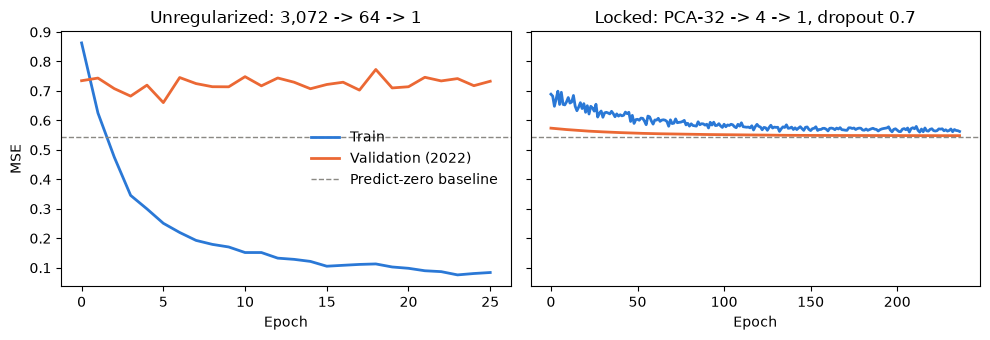

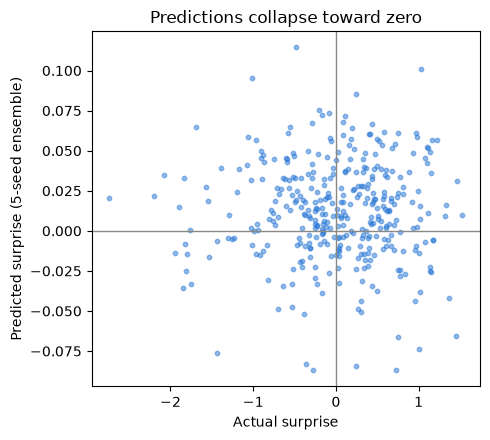

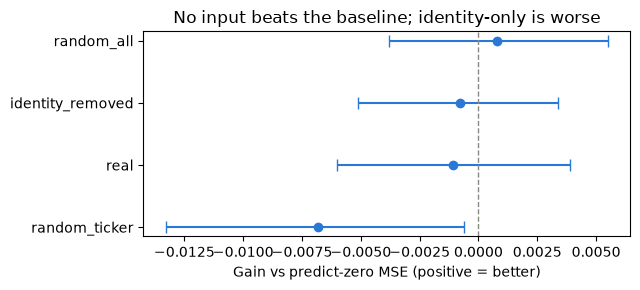

In [14]:
# unregularized vs locked configuration, training curves
m1, h1, _ = train_model(X_std["real"], seed=0)                 
m2, h2, _ = train_model(X_final["real"], seed=0, **CFG)        
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), sharey=True)
for ax, h, title in [(axes[0], h1, "Unregularized: 3,072 -> 64 -> 1"),
                     (axes[1], h2, "Locked: PCA-32 -> 4 -> 1, dropout 0.7")]:
    ax.plot(h["train"], color=BLUE, lw=2, label="Train")
    ax.plot(h["val"], color=ORANGE, lw=2, label="Validation (2022)")
    ax.axhline(mse(np.zeros_like(y_val), y_val), color=MUTED, ls="--", lw=1, label="Predict-zero baseline")
    ax.set(title=title, xlabel="Epoch")
axes[0].set_ylabel("MSE"); axes[0].legend(frameon=False)
plt.tight_layout()
plt.savefig("../results/training_curves.png", dpi=150, bbox_inches="tight")  
plt.show()

# predicted vs actual surprise on the 2023 test set 
fig, ax = plt.subplots(figsize=(5, 4.5))
ax.scatter(y_test, ens_preds["real"], s=10, color=BLUE, alpha=0.5)
ax.axhline(0, color=MUTED, lw=1); ax.axvline(0, color=MUTED, lw=1)
ax.set(xlabel="Actual surprise", ylabel="Predicted surprise (5-seed ensemble)",
       title="Predictions collapse toward zero")
plt.tight_layout()
plt.savefig("../results/pred_vs_actual.png", dpi=150, bbox_inches="tight")   
plt.show()

# gain over the predict-zero baseline, with 95% bootstrap CIs 
order = ci_df.sort_values("gain_vs_zero")
fig, ax = plt.subplots(figsize=(6.5, 3))
ax.errorbar(order["gain_vs_zero"], range(len(order)),
            xerr=[order["gain_vs_zero"] - order["ci_low"], order["ci_high"] - order["gain_vs_zero"]],
            fmt="o", color=BLUE, ecolor=BLUE, capsize=4, ms=6)
ax.axvline(0, color=MUTED, ls="--", lw=1)
ax.set_yticks(range(len(order)), order["input"])
ax.set(xlabel="Gain vs predict-zero MSE (positive = better)",
       title="No input beats the baseline; identity-only is worse")
plt.tight_layout()
plt.savefig("../results/gain_ci.png", dpi=150, bbox_inches="tight")            
plt.show()

Plot 1:
- left side: the unregularized MLP  memorizes the traininsg set. Training MSE falls from 0.86 to 0.08 while validation MSE stays around 0.70-0.75, above the predict zero baselone at every epoch, This is overfitting
- right side: after heavy regularization (PCA to 32 dimensions, 4 hidden units, dropout 0.7), validation MSE declines smoothly toward the baseline and levels off just above it. Training MSE stays near the training set's own variance, so the model learns almost nothing. Training loss sits above validation because dropout is more active during training and the training years are more volatile. Regularization fixed the overfitting but it converges on predicting no surprise

Plot 2
- Actual surprises range from about -2.7 to +1.5, but predictions stay between -0.09 to +0.11. There's no visible slope. Calls that turned out far more or less volatile than usual got the same near zero predictions. The cloud also sits slightly above zero on average, a small positive bias carried over from training. The model has collapsed toward the mean

Plot 3
- For the real, identity removed and random all embeddings, the 95% bootstrap intervals all cross zero. None is distibguishable from predicting zero surprise. Only the random ticker interval lies entirely below zero. A model that knows only which company is speaking does significantly worse than predicting zero because company specific patterns from 2019-2021 don't hold in 2023. Removing identity from the input didn't reveal hidden signal either. 

### Positive Control

In [15]:
### Positive control: can the network predict RAW volatility?

# let the loaders/trainer take any target (default stays the surprise y)
def make_loaders(X, batch_size=64, target=None):
    t = y if target is None else target
    return {s: DataLoader(CallDataset(X[split == s], t[split == s]),
                          batch_size=batch_size, shuffle=(s == "train"))
            for s in ["train", "val", "test"]}

def train_model(X, seed=0, hidden=64, dropout=0.3, opt_name="adam", lr=1e-3, weight_decay=1e-4,
                batch_size=64, max_epochs=200, patience=20, target=None):
    torch.manual_seed(seed); np.random.seed(seed)
    loaders = make_loaders(X, batch_size, target)
    model = make_model(X.shape[1], hidden, dropout)
    opt = (torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay) if opt_name == "adam"
           else torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9, weight_decay=weight_decay))
    loss_fn = nn.MSELoss()
    best_val, best_state, wait, history = float("inf"), None, 0, {"train": [], "val": []}
    for epoch in range(max_epochs):
        history["train"].append(train_one_epoch(model, loaders["train"], opt, loss_fn))
        p_val, t_val = predict(model, loaders["val"])
        history["val"].append(mse(p_val, t_val))
        if history["val"][-1] < best_val:
            best_val, wait = history["val"][-1], 0
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            wait += 1
            if wait >= patience:
                break
    model.load_state_dict(best_state)
    return model, history, loaders

# raw 3-day log volatility, centered on the training mean
y3 = data["y3"].to_numpy(np.float32)
mu_tr = y3[split == "train"].mean()
y_raw = y3 - mu_tr
te = split == "test"

print(f"Global-mean baseline   test MSE {mse(np.zeros(te.sum()), y_raw[te]):.4f}")
print(f"Company baseline       test MSE {mse(data['base3'].to_numpy(np.float32)[te] - mu_tr, y_raw[te]):.4f}")
for name in ["real", "random_ticker", "random_all"]:
    scores = []
    for seed in range(3):
        model, hist, loaders = train_model(X_final[name], seed=seed, hidden=16, dropout=0.3,
                                           lr=1e-3, weight_decay=1e-4, target=y_raw)
        p, t = predict(model, loaders["test"])
        scores.append(mse(p, t))
    print(f"MLP on {name:14s}  test MSE {np.mean(scores):.4f} ± {np.std(scores):.4f}")

Global-mean baseline   test MSE 0.6333
Company baseline       test MSE 0.5411
MLP on real            test MSE 0.6205 ± 0.0059
MLP on random_ticker   test MSE 0.5787 ± 0.0013
MLP on random_all      test MSE 0.6362 ± 0.0063


- Random ticker: 0.579 vs a global mean of 0.633., better. Given only company identity, the network recovers about 60% of the gap between the global mean and the company baseline. So the pipeline can learn real structure
- Random all: 0.636, very close to the global mean. 
- Real embeddings: 0.620, better than the global mean, but only by about 14% of that gap, and weaker than the random ticker. 

The real does worse than the random ticker because the random ticker gives every call from the same company an identical vector, so identity is trivially easy to read. The real embeddings carry identity plus call to call variation, and they were compressed to 32 PCA dimensions. 

## Testing raw volatility target with more dimensions

In [16]:
for label, Xin in [("real, PCA-128", pca_inputs(X_std["real"], 128)),
                   ("real, full 3072", X_std["real"])]:
    scores = []
    for seed in range(3):
        model, hist, loaders = train_model(Xin, seed=seed, hidden=16, dropout=0.3,
                                           lr=1e-3, weight_decay=1e-4, target=y_raw)
        p, t = predict(model, loaders["test"])
        scores.append(mse(p, t))
    print(f"MLP on {label:16s}  test MSE {np.mean(scores):.4f} ± {np.std(scores):.4f}")

MLP on real, PCA-128     test MSE 0.6415 ± 0.0048
MLP on real, full 3072   test MSE 0.6430 ± 0.0188


Failure Analysis
- Overfitting
- Collapse to zero
- Identity reliance
- Missed real events
- Label artifacts